# Ödev 2 — Doğruluğu artırma yöntemleri ve her algoritmanın ROC eğrileri

Bu not defteri `improve_accuracy.py` deneyinin sonuçlarını adım adım gösterir. Her algoritmaya iyileştirme yöntemleri birikimli olarak eklenmiştir:

| Aşama | Yöntem |
|---|---|
| A0 | Temel: ham metin + CountVectorizer + varsayılan parametreler |
| A1 | + Ön işleme & TF-IDF |
| A2 | + Kelime 1-2 gram, karakter 3-5 gram, meta özellikler |
| A3 | + χ² özellik seçimi & GridSearch hiperparametre optimizasyonu |
| A4 | + Karar eşiği optimizasyonu |
| Topluluk | Soft Voting, Stacking, XGBoost, LightGBM |

In [1]:
import pandas as pd
from IPython.display import Image, display
from pathlib import Path
R = Path('results')
pd.set_option('display.float_format', '{:.4f}'.format)

## 1. Aşama bazında test doğruluğu (Enron-Spam, 5.800 test e-postası)

In [2]:
pd.read_csv(R / 'accuracy_by_stage.csv', index_col=0)

,A0,A1,A2,A3,A4,Kazanç (A4-A0),Hata azalması %
Model,,,,,,,
Logistic Regression,0.9867,0.9843,0.9898,0.9922,0.9929,0.0062,46.7532
Linear SVM,0.9807,0.9917,0.9929,0.9926,0.9928,0.0121,62.5000
Naive Bayes,0.9898,0.9874,0.9881,0.9926,0.9926,0.0028,27.1186
Random Forest,0.9814,0.9857,0.9833,0.9826,0.9838,0.0024,12.9630
KNN,0.9060,0.6005,0.9034,0.9824,0.9834,0.0774,82.3853
Decision Tree,0.9484,0.9607,0.9336,0.9402,0.9402,-0.0083,-16.0535


## 2. Topluluk (ensemble) yöntemleri

In [3]:
pd.read_csv(R / 'ensemble_results.csv')[['Model', 'Accuracy', 'F1', 'ROC-AUC', 'Hata sayısı']]

,Model,Accuracy,F1,ROC-AUC,Hata sayısı
0,Soft Voting (NB+LR+SVM+RF),0.9947,0.9947,0.9995,31
1,Stacking (meta: LR),0.9948,0.9948,0.9996,30
2,XGBoost,0.9833,0.9834,0.9991,97
3,LightGBM,0.9862,0.9863,0.9992,80


## 3. Her iyileştirme adımının etkisi

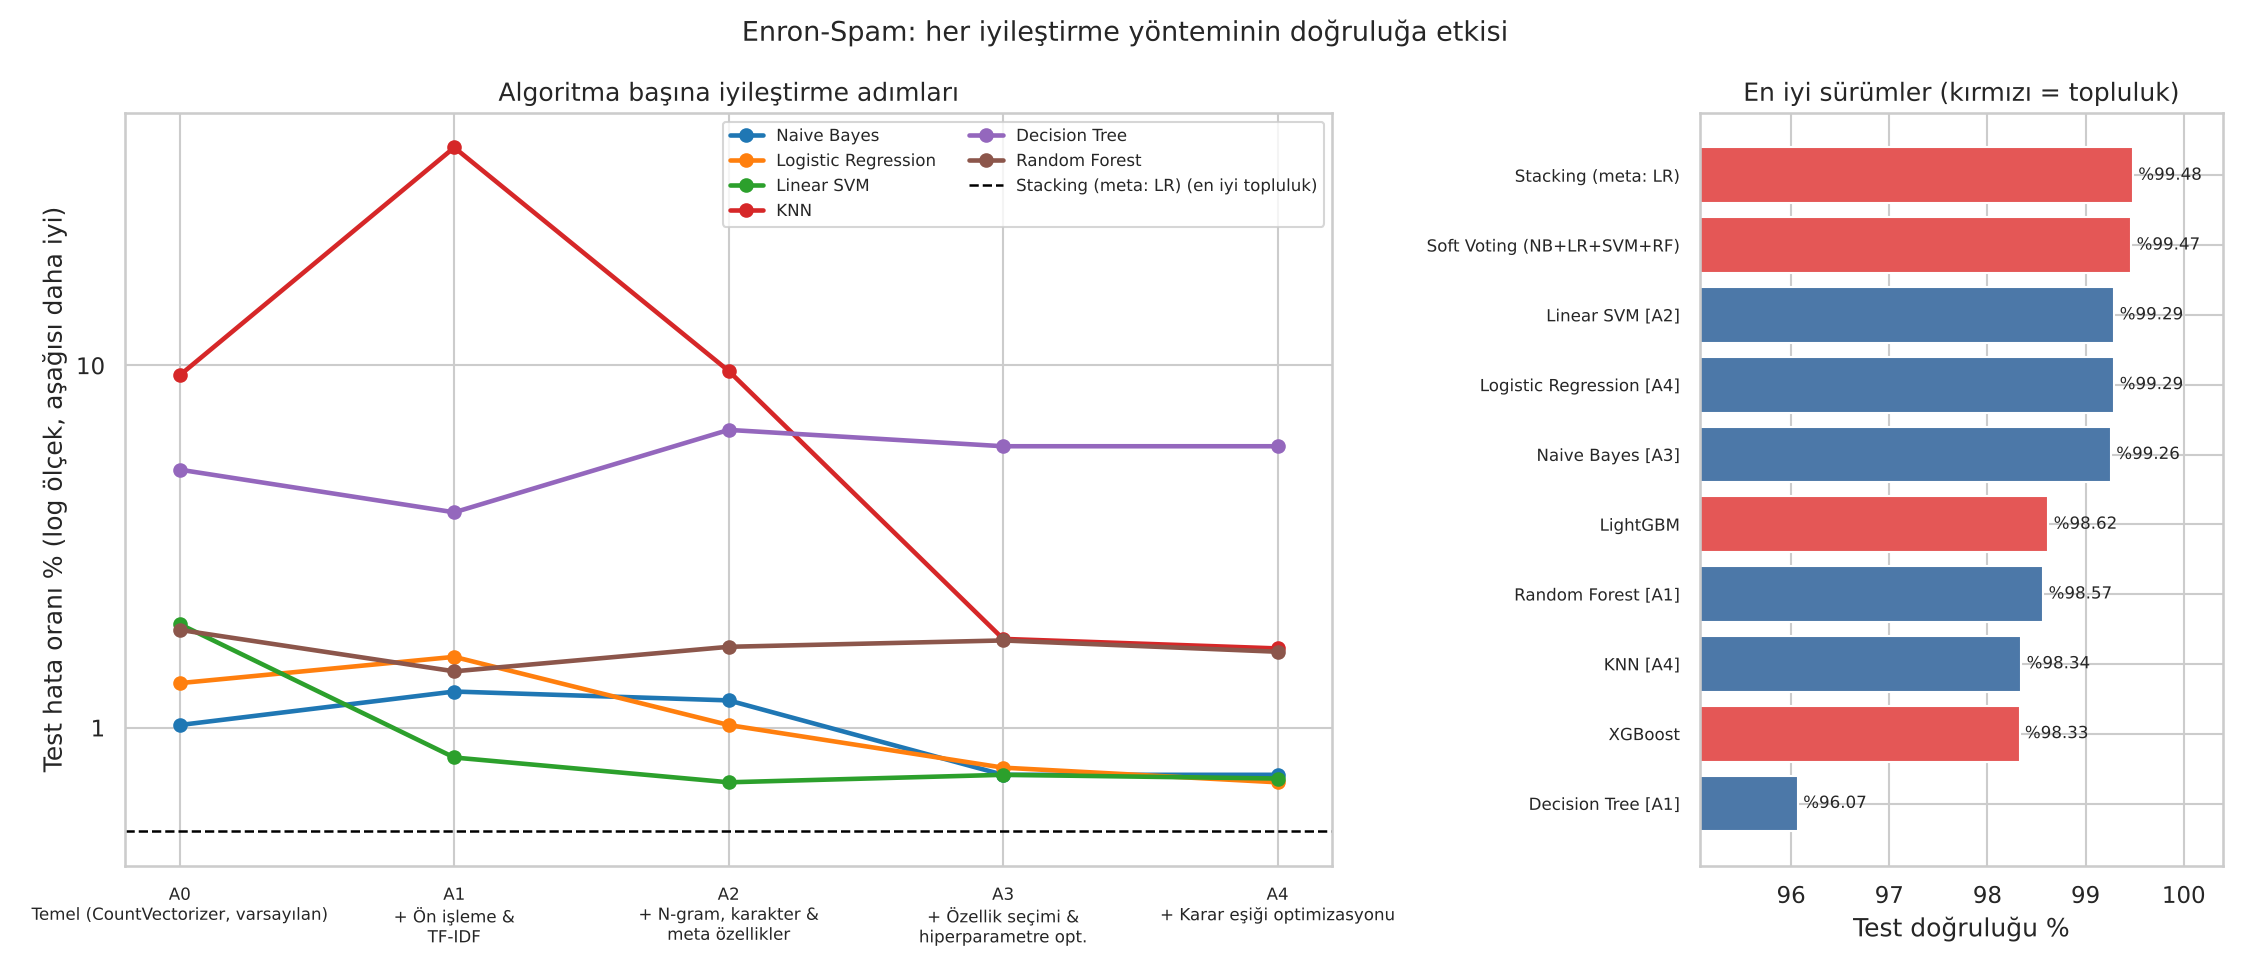

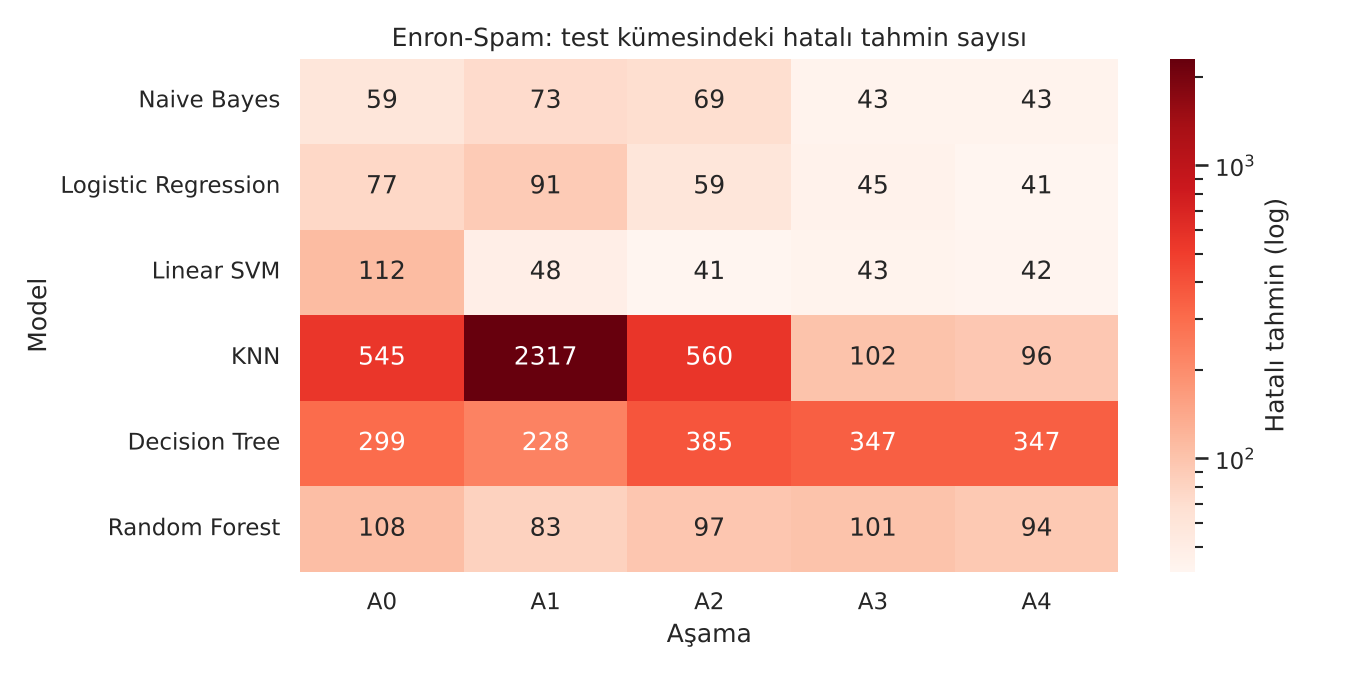

In [4]:
display(Image(filename=str(R / 'accuracy_ladder.png')))
display(Image(filename=str(R / 'errors_heatmap.png')))

## 4. Her algoritmanın ROC eğrisi

Sol: klasik ROC. Sağ: FPR ekseni log ölçekte (sol üst köşe büyütülmüş). ● varsayılan eşik, ★ optimize edilmiş eşik (A4).

roc_decision_tree


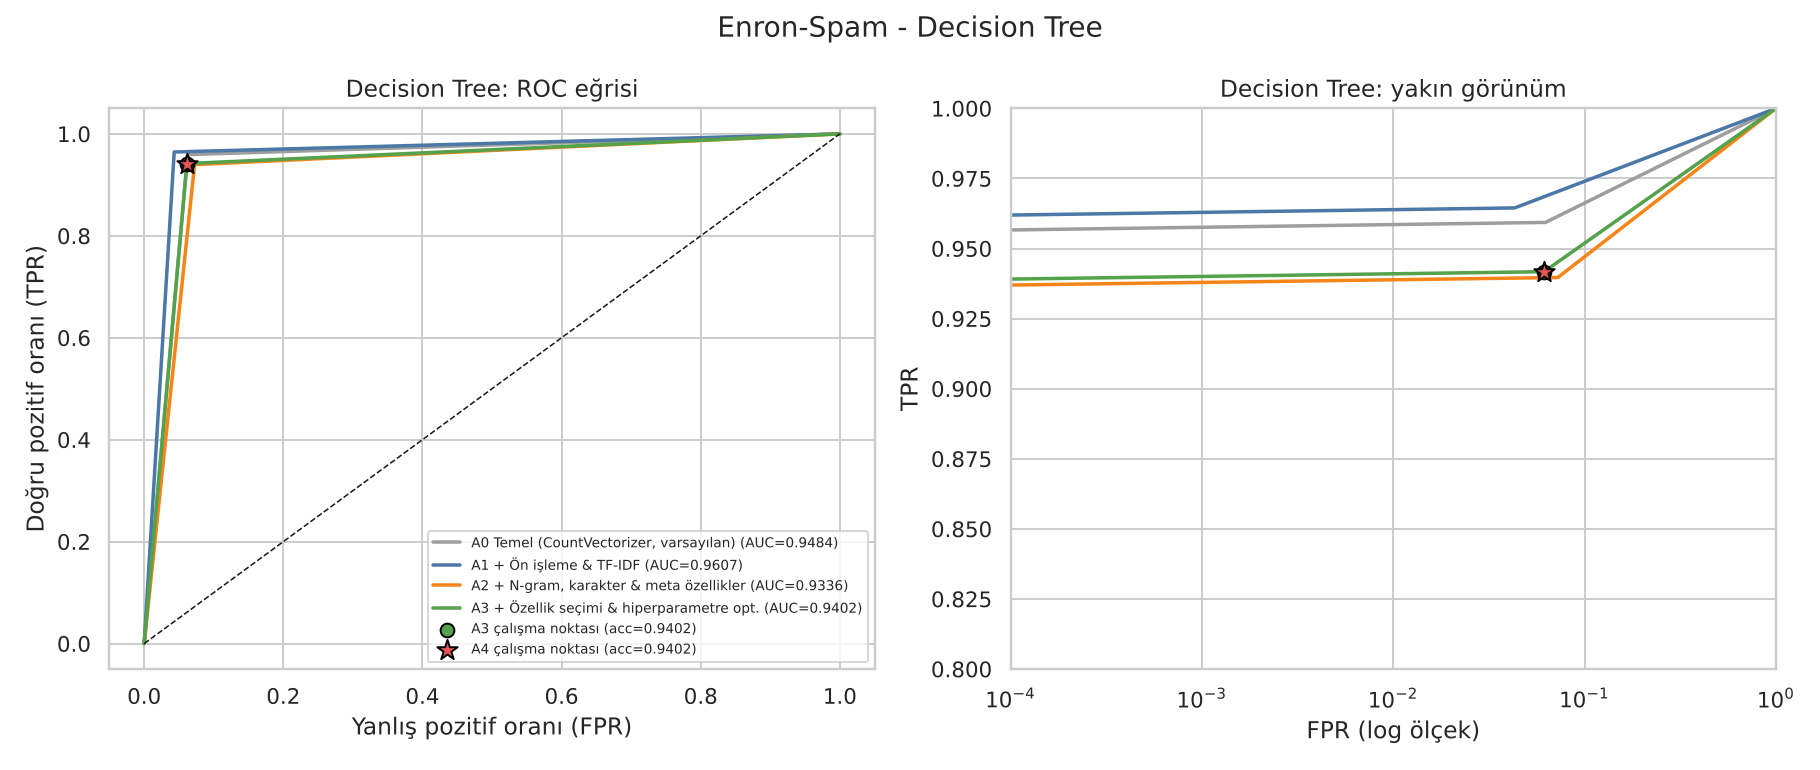

roc_knn


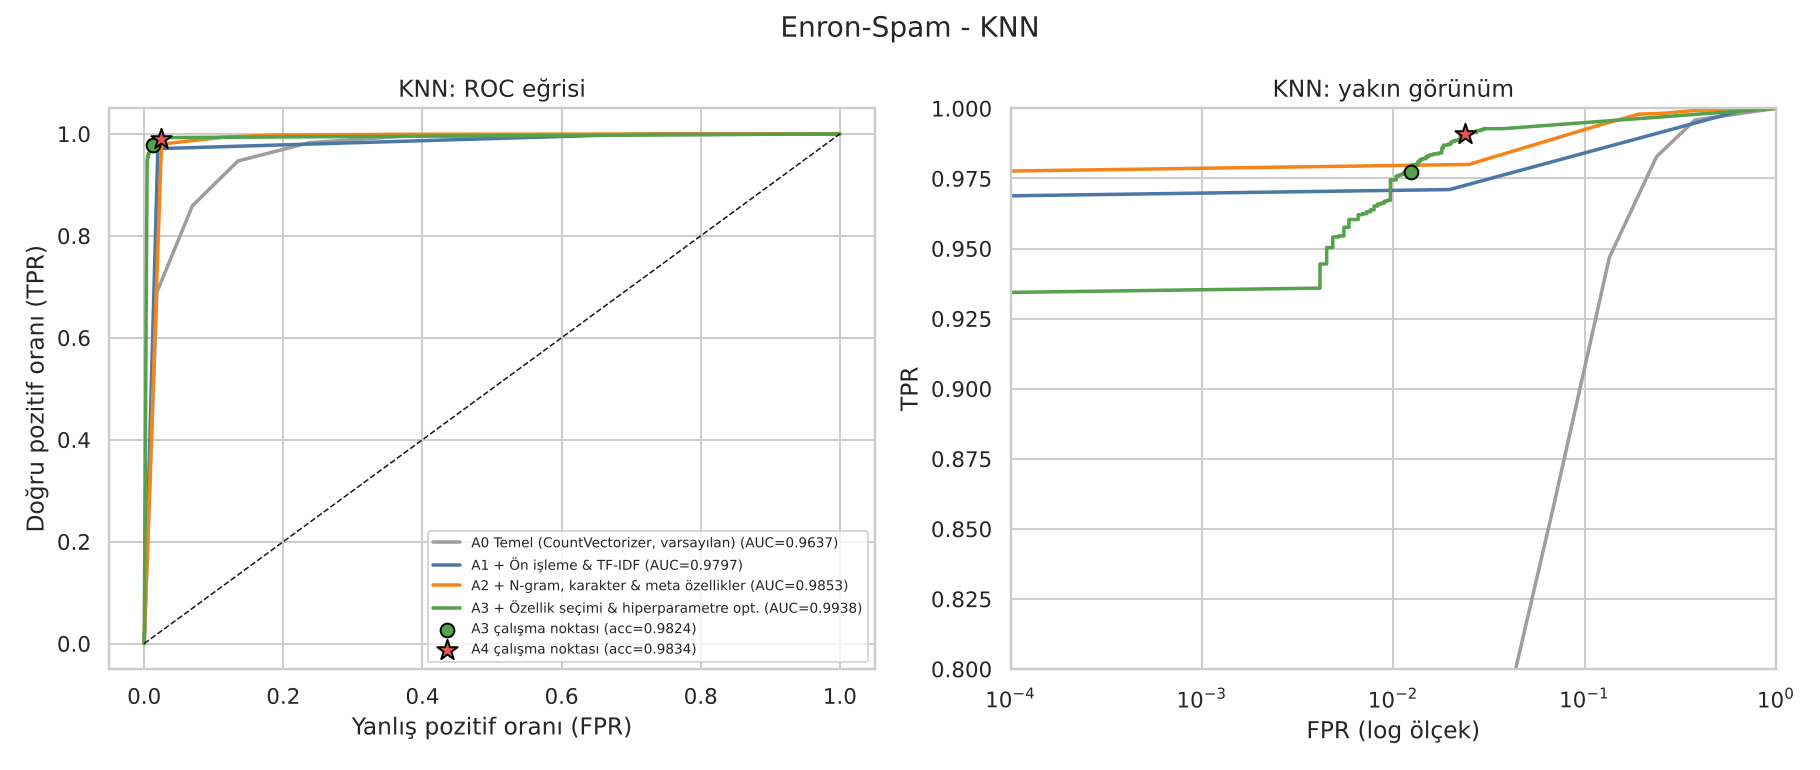

roc_linear_svm


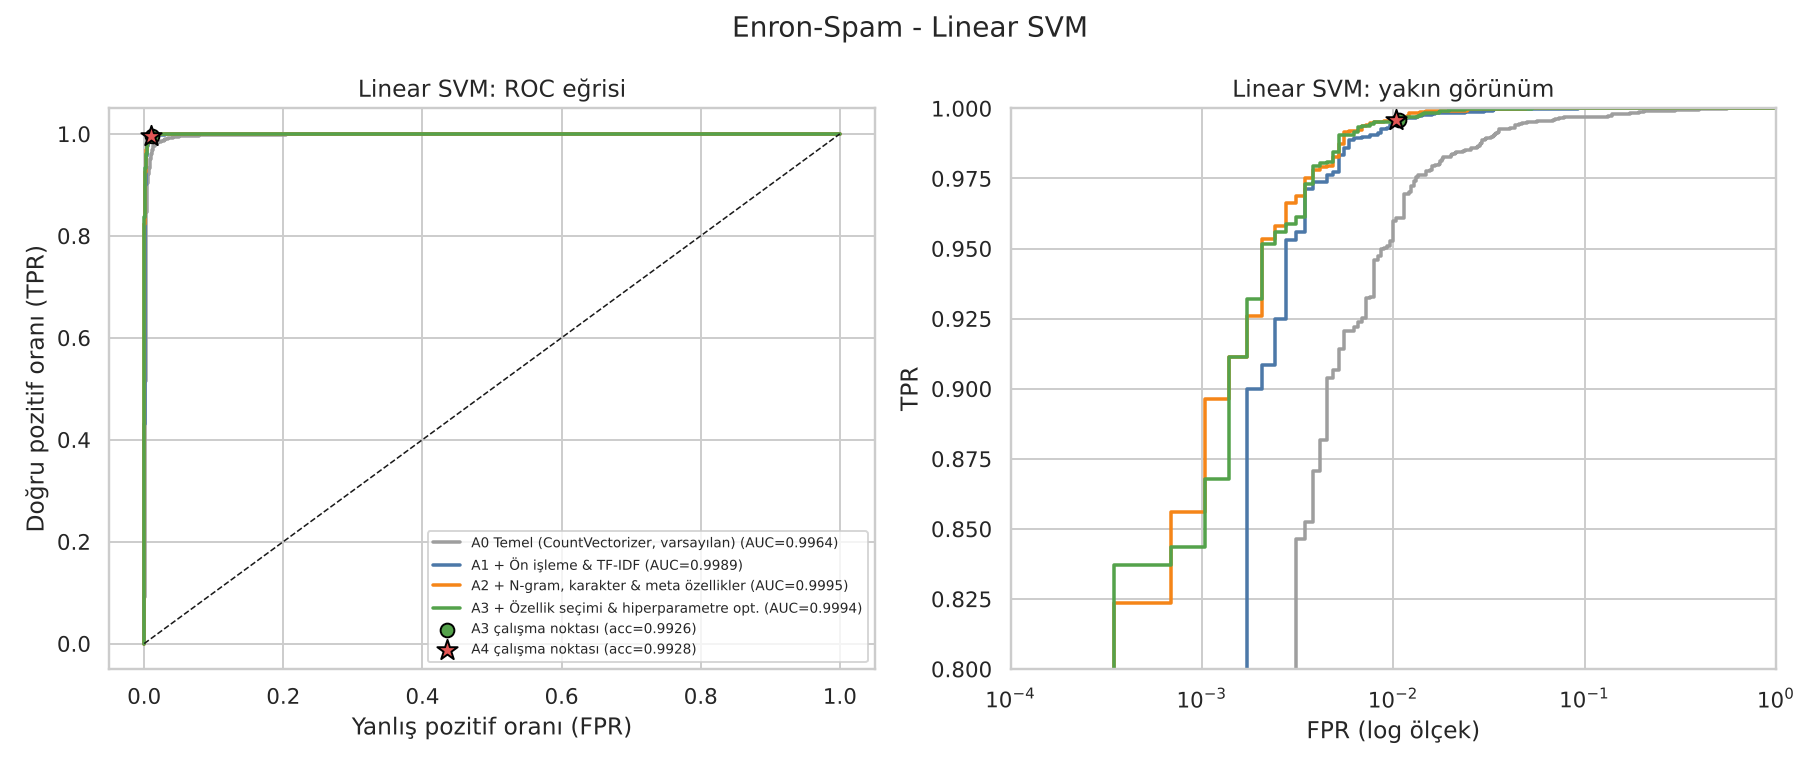

roc_logistic_regression


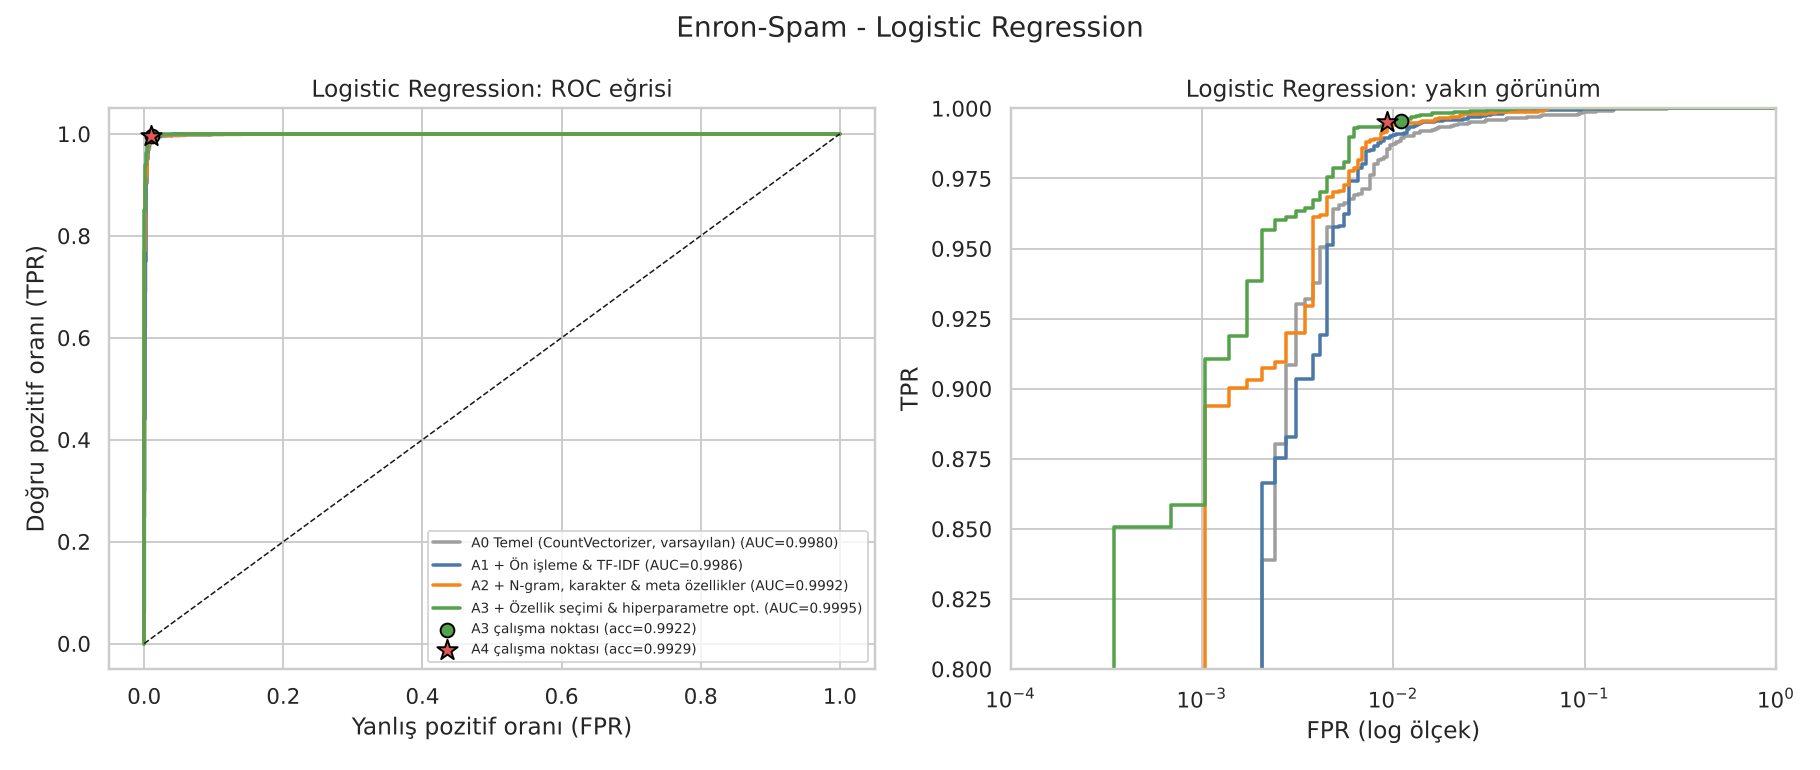

roc_naive_bayes


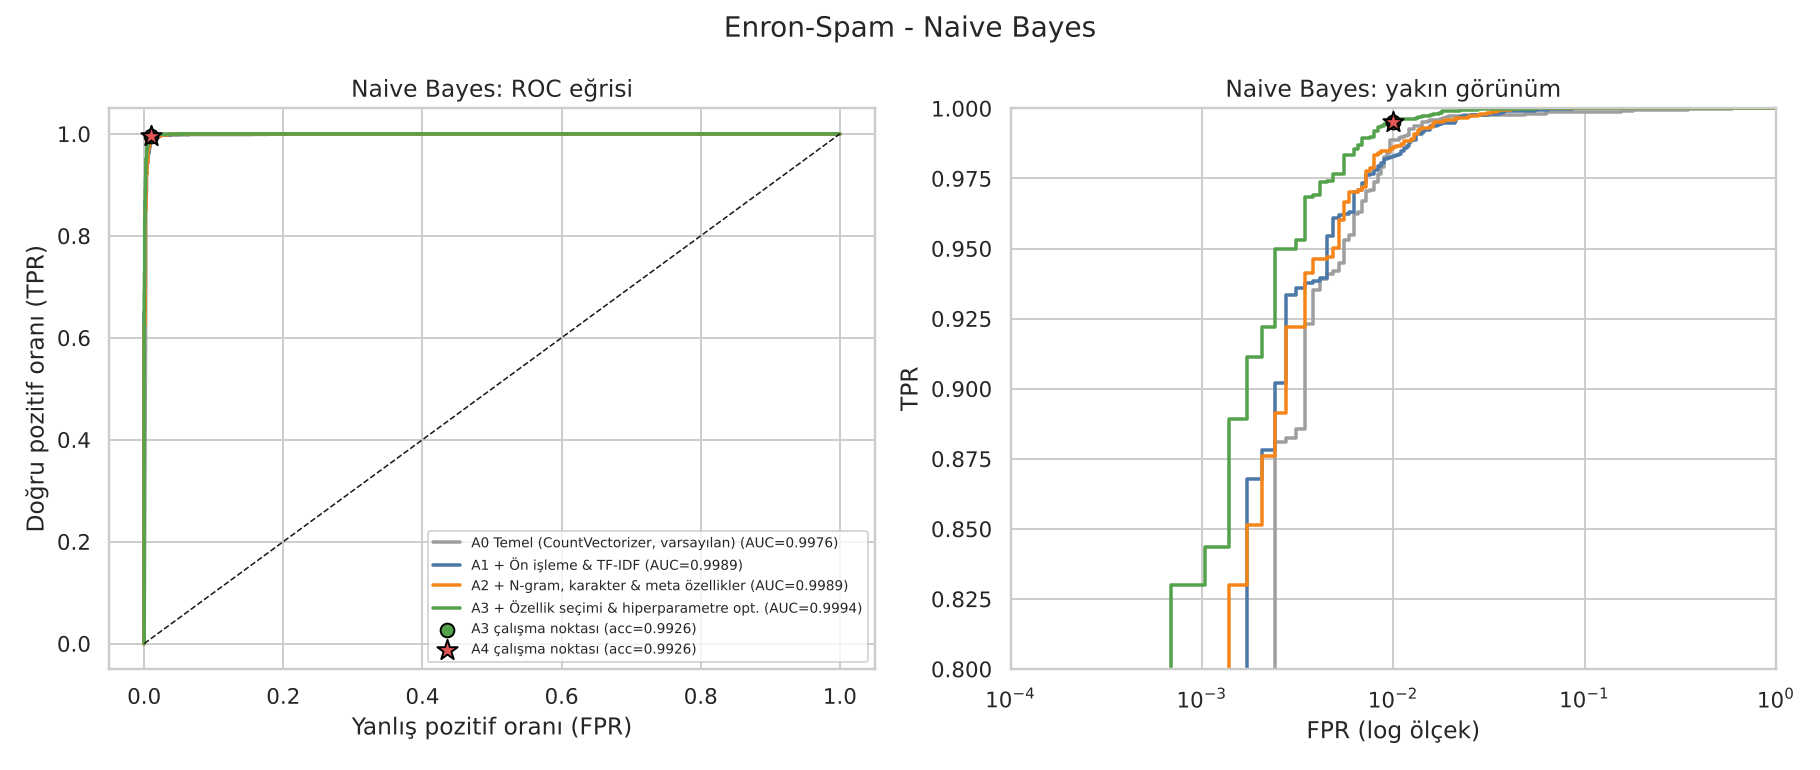

roc_random_forest


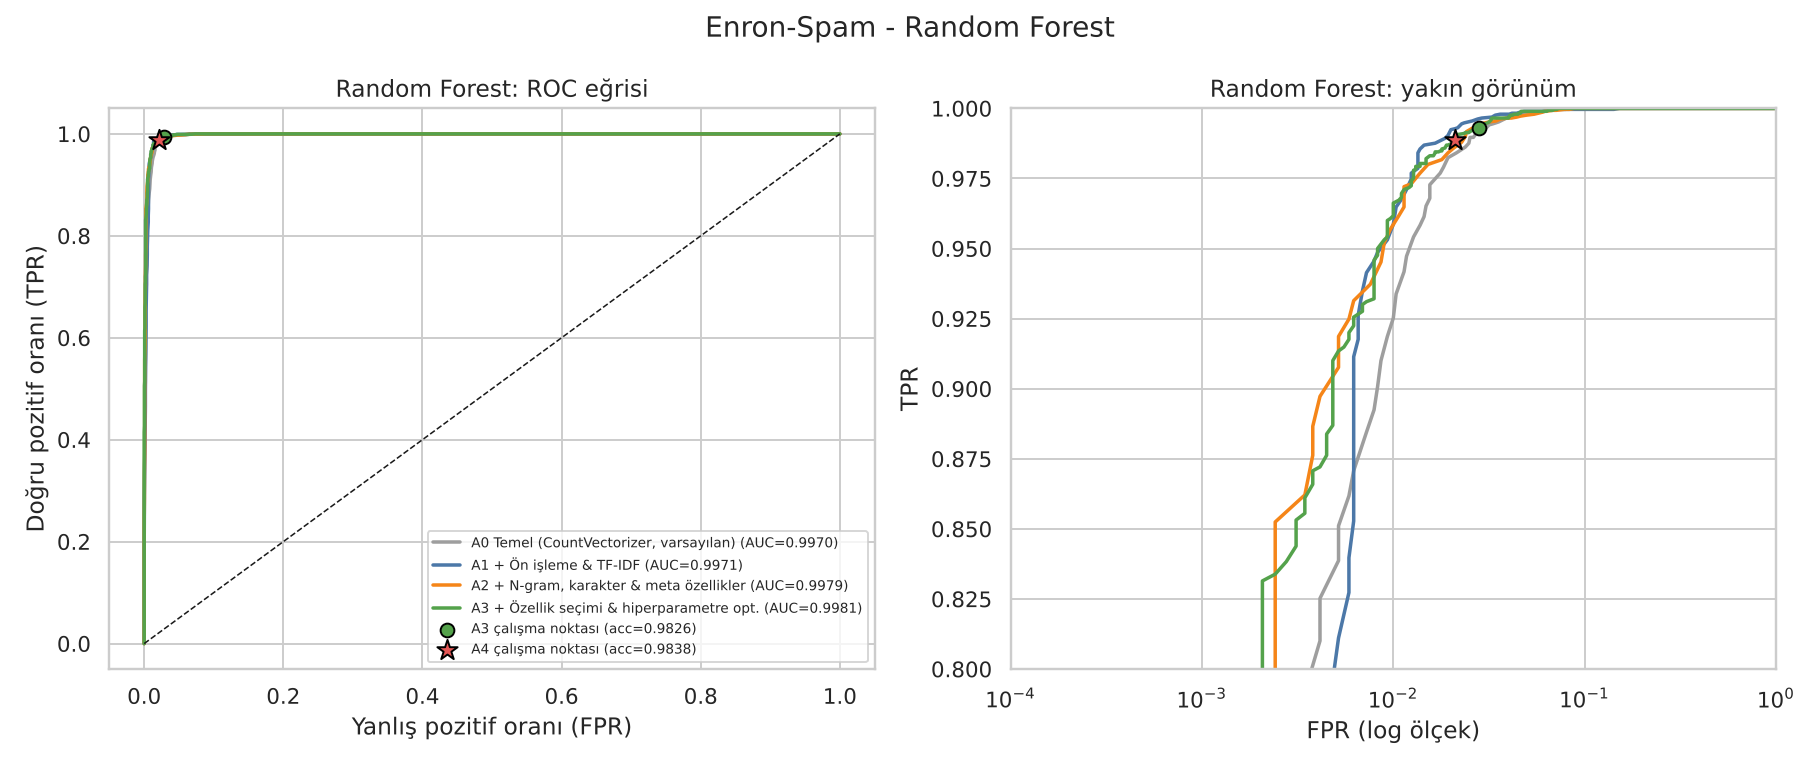

In [5]:
for f in sorted((R / 'roc').glob('roc_*.png')):
    print(f.stem)
    display(Image(filename=str(f)))

### Tüm algoritmalar tek sayfada

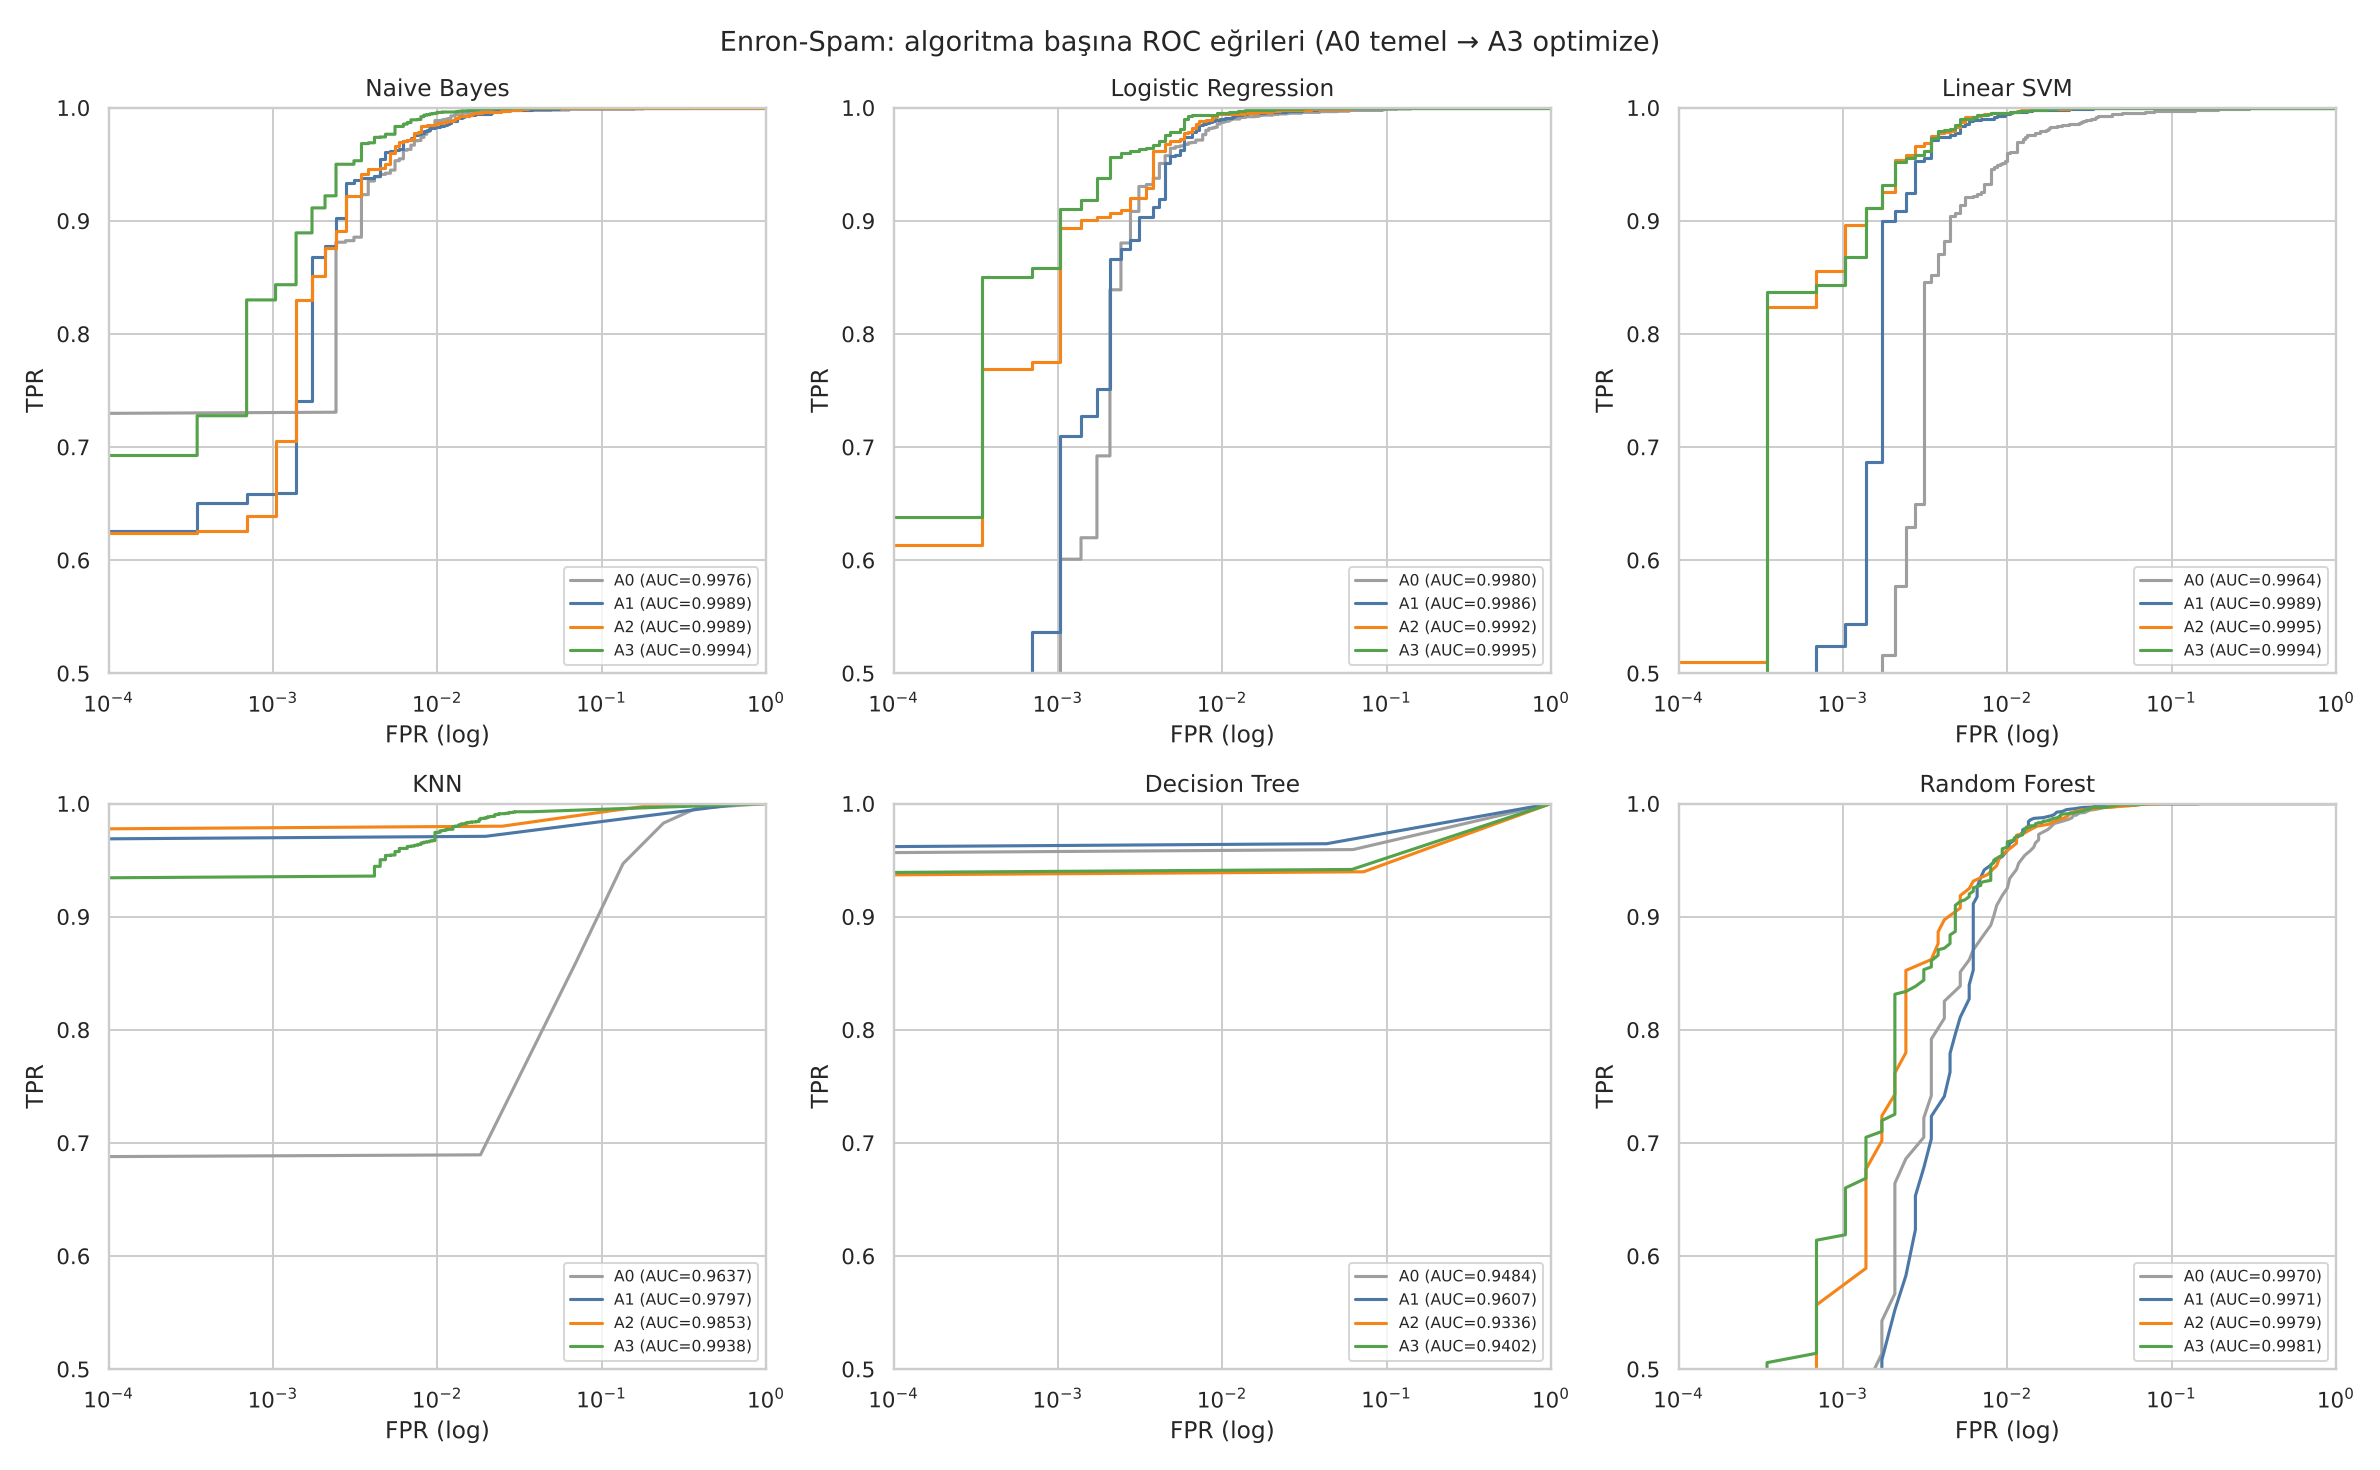

In [6]:
display(Image(filename=str(R / 'roc_all_algorithms.png')))

### Optimize modeller ve topluluklar

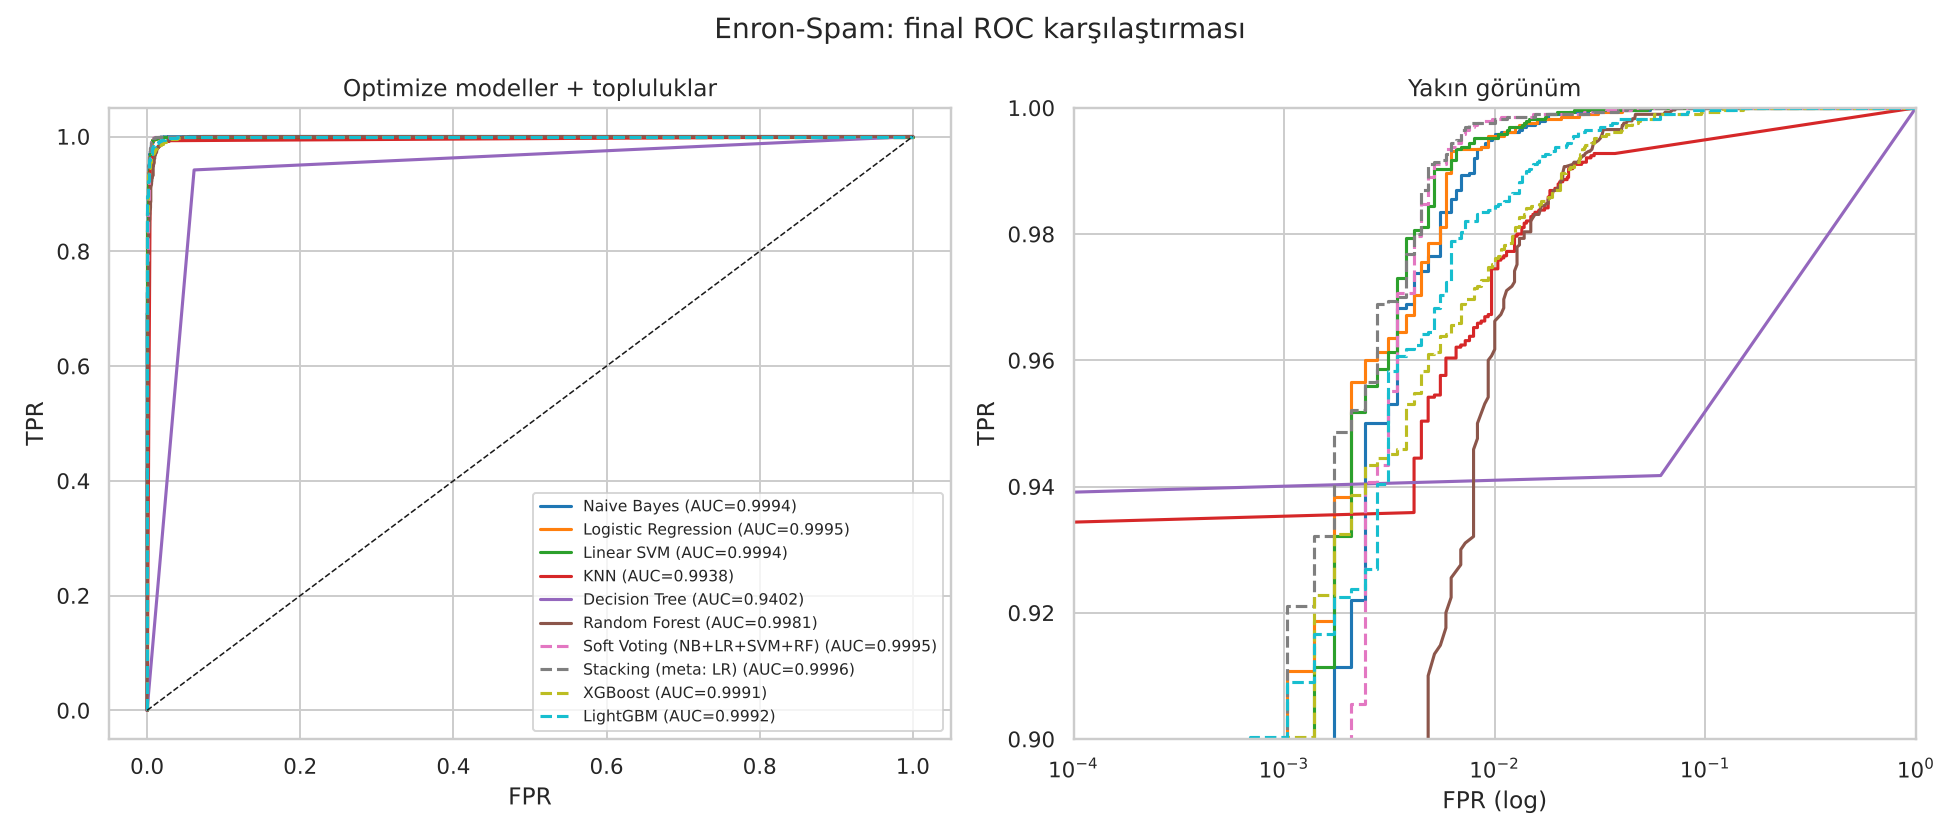

In [7]:
display(Image(filename=str(R / 'roc_final_comparison.png')))

## 5. İstatistiksel anlamlılık (McNemar testi)

En doğru model; en iyi tek model, tüm temel (A0) modeller ve diğer topluluklarla aynı test örnekleri üzerinde karşılaştırılır.

In [8]:
pd.read_csv(R / 'mcnemar.csv')

,Karşılaştırma,Yalnız ilki doğru,Yalnız ikincisi doğru,p-değeri,Anlamlı (p<0.05)
0,Stacking (meta: LR) [Ensemble] vs Logistic Reg...,16,5,0.0266,True
1,Stacking (meta: LR) [Ensemble] vs Naive Bayes ...,39,10,0.0000,True
2,Stacking (meta: LR) [Ensemble] vs Logistic Reg...,55,8,0.0000,True
3,Stacking (meta: LR) [Ensemble] vs Linear SVM [A0],92,10,0.0000,True
4,Stacking (meta: LR) [Ensemble] vs KNN [A0],524,9,0.0000,True
5,Stacking (meta: LR) [Ensemble] vs Decision Tre...,276,7,0.0000,True
6,Stacking (meta: LR) [Ensemble] vs Random Fores...,85,7,0.0000,True
7,Stacking (meta: LR) [Ensemble] vs Soft Voting ...,3,2,1.0000,False
8,Stacking (meta: LR) [Ensemble] vs XGBoost [Ens...,76,9,0.0000,True
9,Stacking (meta: LR) [Ensemble] vs LightGBM [En...,59,9,0.0000,True


## 6. Genelleme kontrolü: SMS Spam Collection

,A0,A1,A2,A3,A4,Kazanç (A4-A0),Hata azalması %
Model,,,,,,,
Logistic Regression,0.9745,0.9735,0.9833,0.9872,0.9863,0.0118,46.1538
Linear SVM,0.9794,0.9843,0.9853,0.9843,0.9853,0.0059,28.5714
KNN,0.9127,0.9185,0.9686,0.9853,0.9843,0.0716,82.0225
Naive Bayes,0.9784,0.9676,0.9774,0.9755,0.9833,0.0049,22.7273
Random Forest,0.9696,0.9764,0.9823,0.9814,0.9823,0.0128,41.9355
Decision Tree,0.9676,0.9647,0.9715,0.9715,0.9696,0.0020,6.0606


,Model,Accuracy,F1,ROC-AUC,Hata sayısı
0,Soft Voting (NB+LR+SVM+RF),0.9872,0.9432,0.9913,13
1,Stacking (meta: LR),0.9863,0.9391,0.9929,14
2,XGBoost,0.9804,0.9115,0.9889,20
3,LightGBM,0.9813,0.9156,0.9887,19


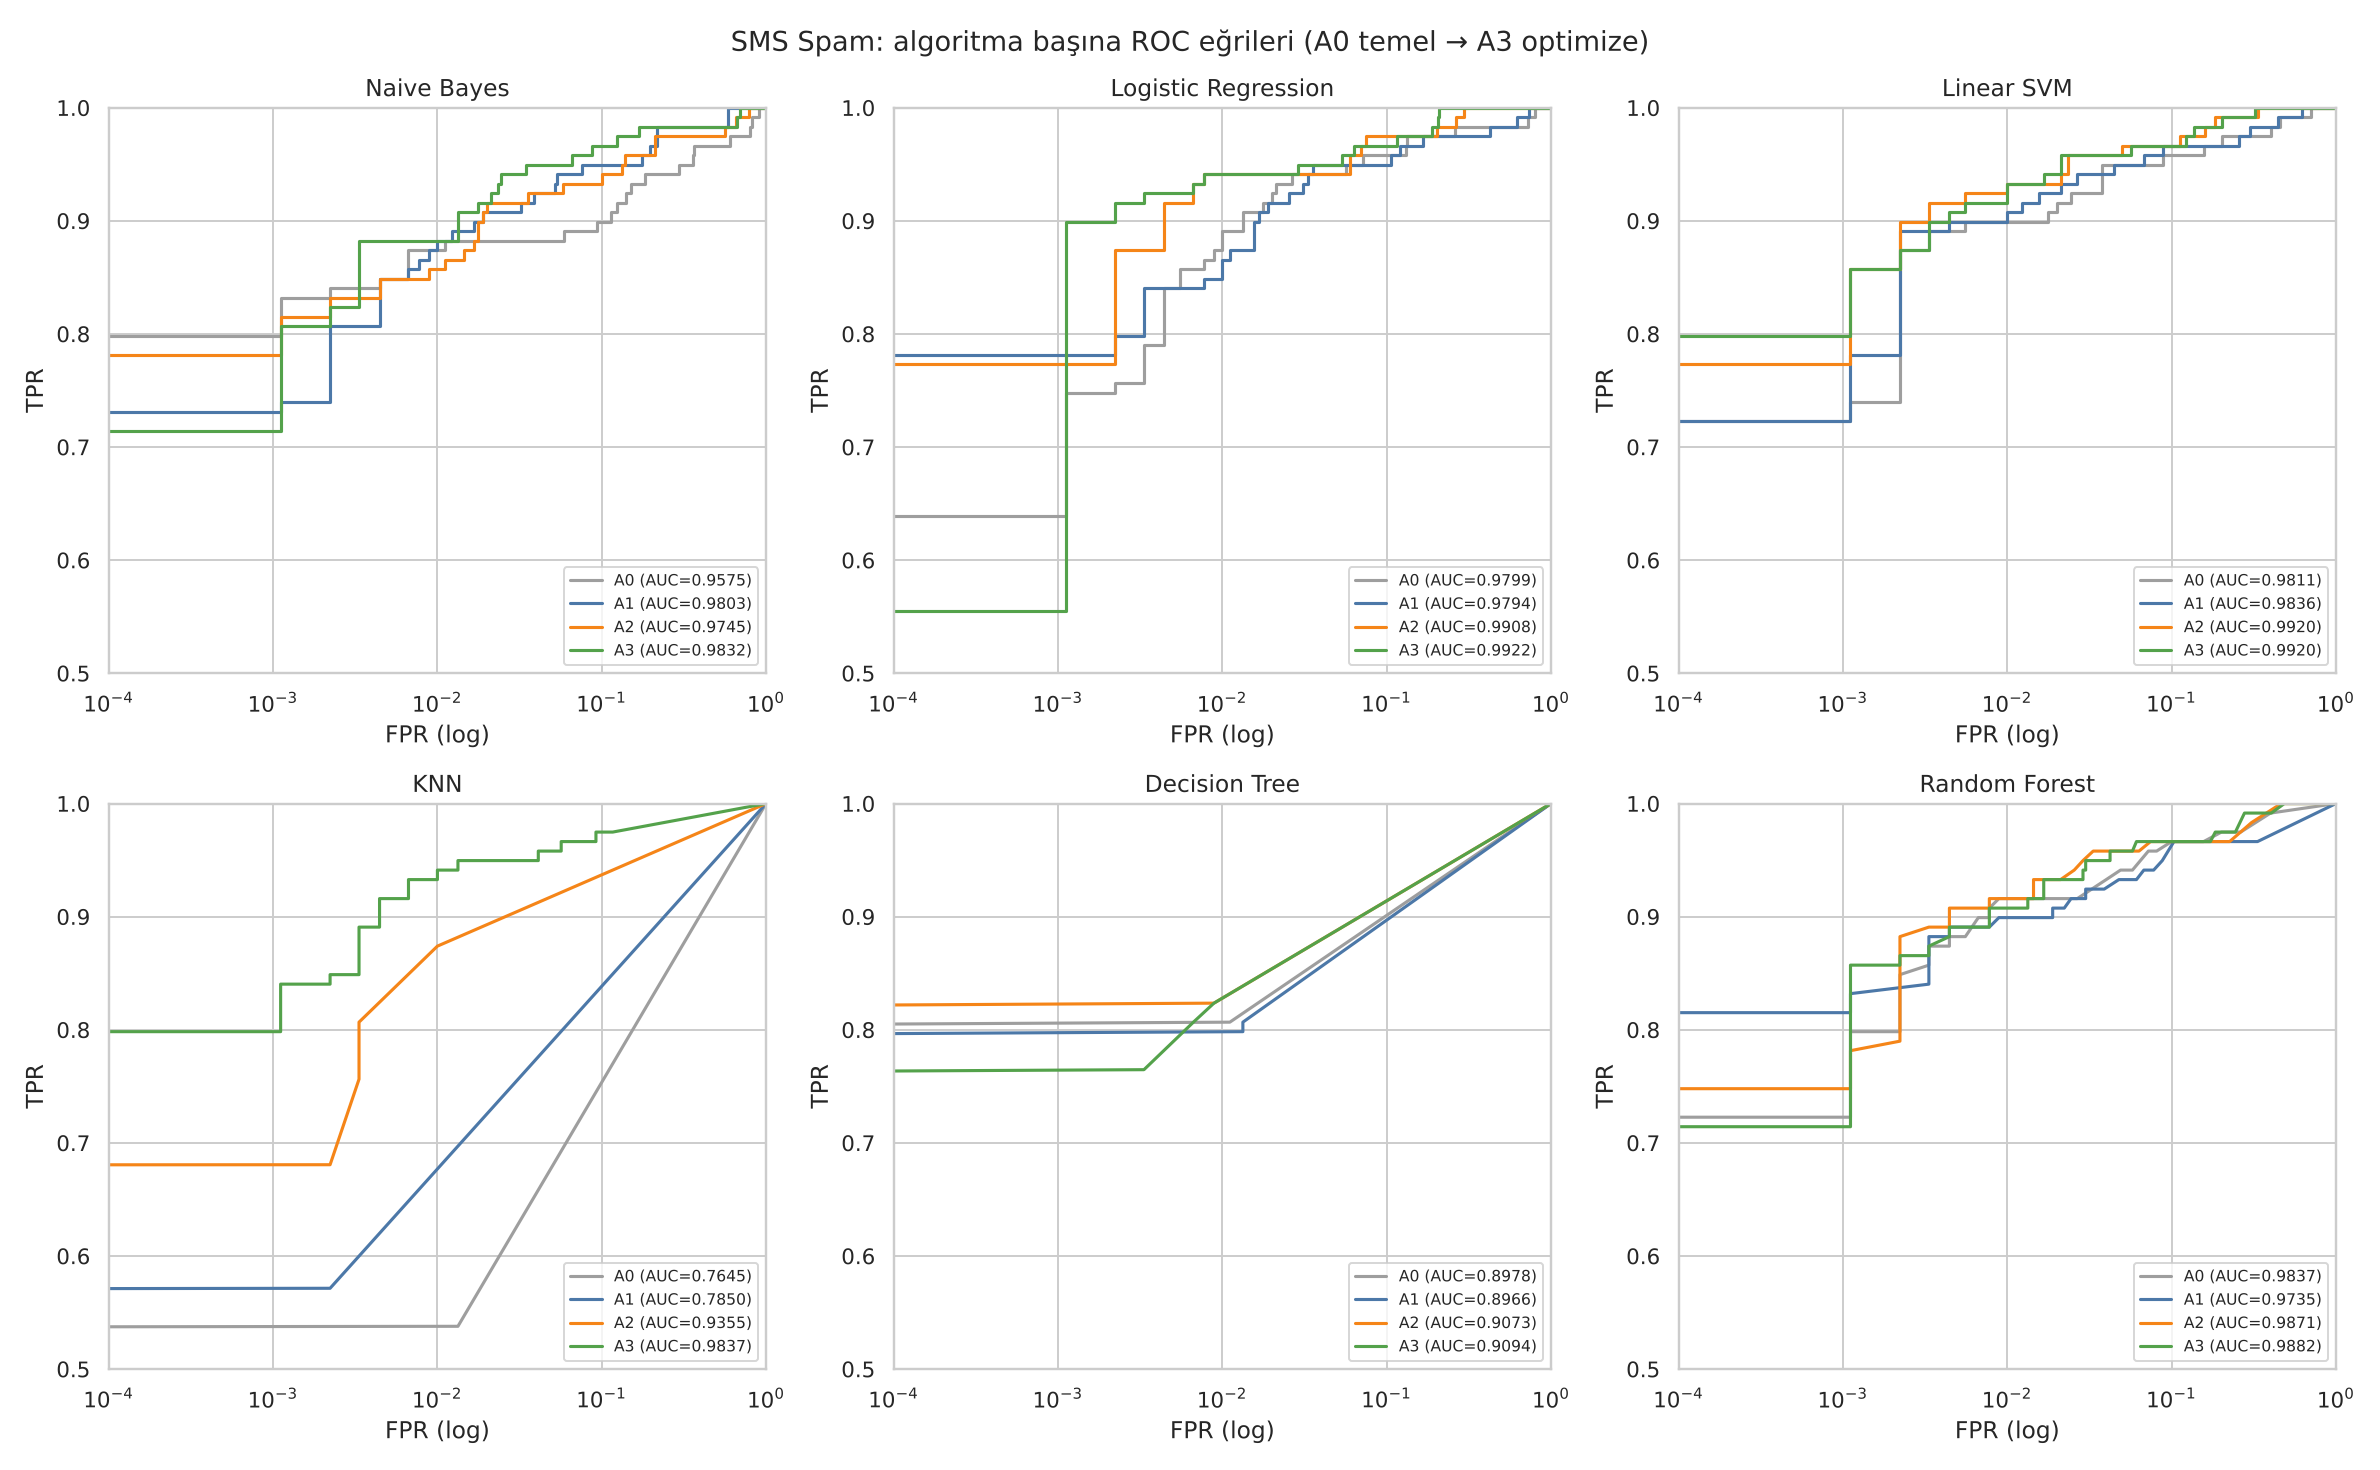

In [9]:
display(pd.read_csv(R / 'sms' / 'accuracy_by_stage.csv', index_col=0))
display(pd.read_csv(R / 'sms' / 'ensemble_results.csv')[['Model', 'Accuracy', 'F1', 'ROC-AUC', 'Hata sayısı']])
display(Image(filename=str(R / 'sms' / 'roc_all_algorithms.png')))

## 7. Sonuç

In [10]:
print(open(R / 'summary.txt', encoding='utf-8').read())

Enron-Spam
Test doğruluğu (aşama bazında):
Aşama                   A0     A1     A2     A3     A4  Kazanç (A4-A0)  Hata azalması %
Model                                                                                  
Logistic Regression 0.9867 0.9843 0.9898 0.9922 0.9929          0.0062          46.7532
Linear SVM          0.9807 0.9917 0.9929 0.9926 0.9928          0.0121          62.5000
Naive Bayes         0.9898 0.9874 0.9881 0.9926 0.9926          0.0028          27.1186
Random Forest       0.9814 0.9857 0.9833 0.9826 0.9838          0.0024          12.9630
KNN                 0.9060 0.6005 0.9034 0.9824 0.9834          0.0774          82.3853
Decision Tree       0.9484 0.9607 0.9336 0.9402 0.9402         -0.0083         -16.0535

Topluluk yöntemleri:
                     Model  Accuracy     F1  ROC-AUC  Hata sayısı
Soft Voting (NB+LR+SVM+RF)    0.9947 0.9947   0.9995           31
       Stacking (meta: LR)    0.9948 0.9948   0.9996           30
                   XGBoost    0.9